# STRATUM — Semiconductor Material Properties EDA

### Objective

Investigate the physical and electrical characteristics of AlCu thin films deposited using Physical Vapor Deposition (PVD).

### Properties Studied

1. Mean film thickness
2. Mean sheet resistance
3. Derived resistivity
4. Seventeen-point wafer measurement profiles
5. Wafer-level quality classifications

### Research Questions

- How much does deposited film thickness vary?
- How does sheet resistance vary across wafers?
- What relationship exists between thickness and resistance?
- How consistent are measurements across the wafer?
- Can a wafer pass thickness quality checks but fail
  other material-property checks?

### Important Notes

The original dataset is not modified.

Engineering units and undisclosed industrial acceptance limits will not be assumed.

All findings are based on historical Infineon AlCu manufacturing equipment-testing data.

In [1]:
# Import libraries

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the original dataset
filename = "apc_spc_AlCu_inputs_outputs.csv"

current_dir = Path.cwd()

csv_path = current_dir / "data" / "raw" / filename

if not csv_path.exists():
    csv_path = current_dir.parent / "data" / "raw" / filename

if not csv_path.exists():
    raise FileNotFoundError("Infineon dataset not found.")

# Load data without modifying the original CSV
df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False
)

print("STRATUM - Material Properties EDA")
print("Dataset shape:", df.shape)
print("Dataset loaded successfully!")

STRATUM - Material Properties EDA
Dataset shape: (5208, 178)
Dataset loaded successfully!


## 1. Wafer-Level Property Statistics

Examine the central tendency, spread and observed range of the measured material properties.

In [2]:
# Descriptive statistics

properties = [
    "mean_thickness",
    "mean_resistance"
]

summary = df[properties].describe().T

summary["missing_values"] = (
    df[properties].isna().sum()
)

display(summary.round(6))

,count,mean,std,min,25%,50%,75%,max,missing_values
mean_thickness,5208.0,152.094096,2.485393,141.962074,150.446296,152.177426,153.745453,163.641800,0
mean_resistance,5208.0,0.002899,0.000053,0.002705,0.002864,0.002895,0.002931,0.003223,0


## 2. Thickness Distribution

Visualise the distribution of mean AlCu film thickness and investigate the spread of wafer-level measurements.

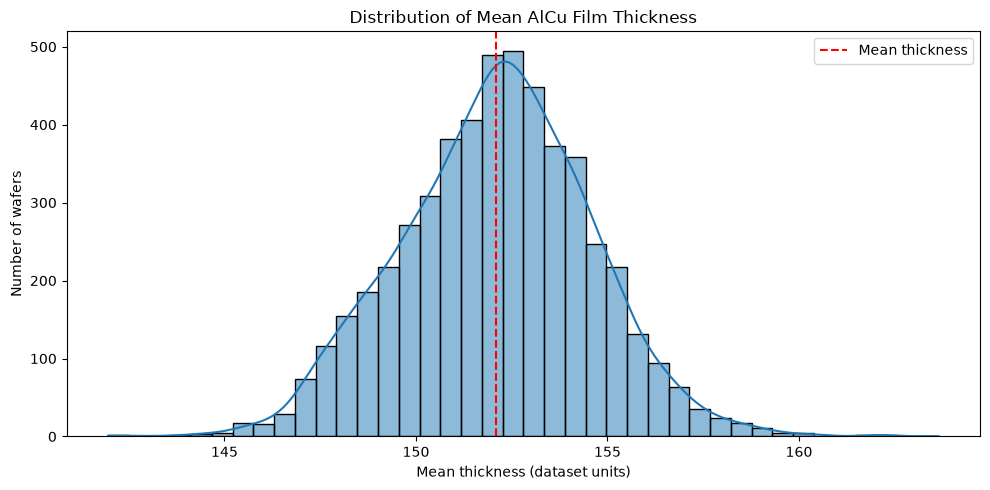

In [3]:
# Mean thickness distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="mean_thickness",
    bins=40,
    kde=True
)

plt.axvline(
    df["mean_thickness"].mean(),
    color="red",
    linestyle="--",
    label="Mean thickness"
)

plt.title("Distribution of Mean AlCu Film Thickness")
plt.xlabel("Mean thickness (dataset units)")
plt.ylabel("Number of wafers")
plt.legend()

plt.tight_layout()
plt.show()


## 3. Sheet Resistance Distribution

Analyse the distribution and variability of measured wafer-level sheet resistance.

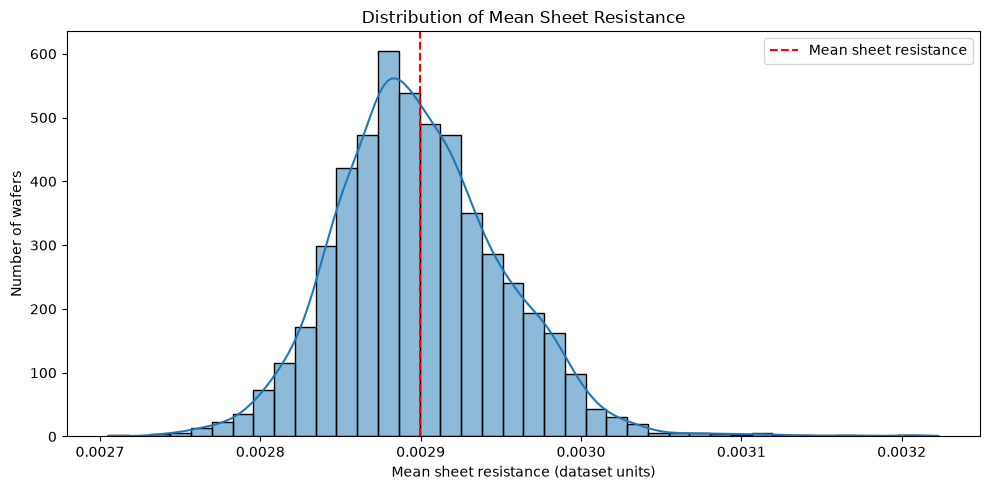

In [4]:
# Sheet resistance distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="mean_resistance",
    bins=40,
    kde=True
)

plt.axvline(
    df["mean_resistance"].mean(),
    color="red",
    linestyle="--",
    label="Mean sheet resistance"
)

plt.title("Distribution of Mean Sheet Resistance")
plt.xlabel("Mean sheet resistance (dataset units)")
plt.ylabel("Number of wafers")
plt.legend()

plt.tight_layout()
plt.show()


## 4. Thickness–Resistance Relationship

Investigate the statistical association between average film thickness and average sheet resistance.

Correlation does not establish causation.

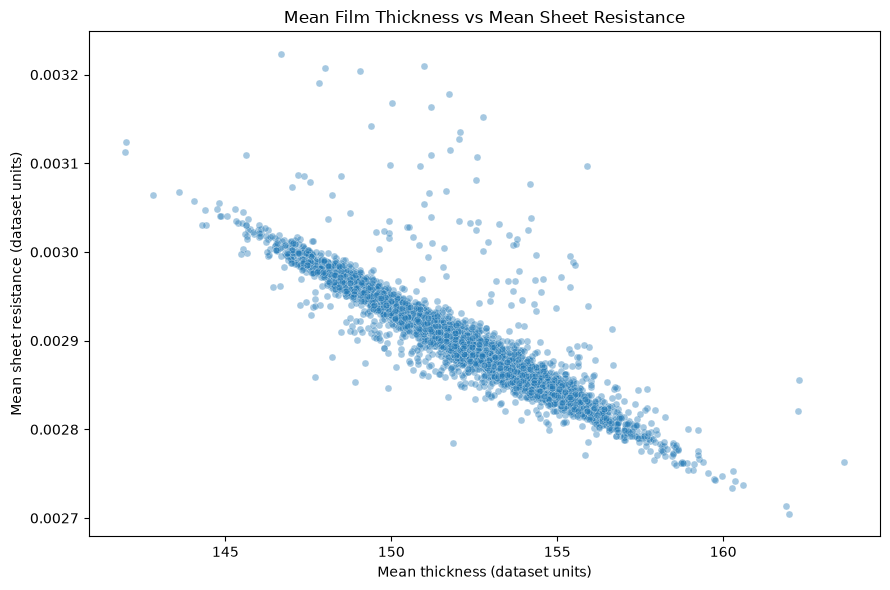

Pearson correlation: -0.8999


In [5]:
# Thickness vs sheet resistance

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="mean_thickness",
    y="mean_resistance",
    alpha=0.4,
    s=25
)

plt.title("Mean Film Thickness vs Mean Sheet Resistance")
plt.xlabel("Mean thickness (dataset units)")
plt.ylabel("Mean sheet resistance (dataset units)")

plt.tight_layout()
plt.show()

# Calculate Pearson correlation
correlation = df[
    ["mean_thickness", "mean_resistance"]
].corr().iloc[0, 1]

print(
    f"Pearson correlation: {correlation:.4f}"
)


## 5. Seventeen-Point Wafer Measurement Profiles

Examine measured material properties across the 17 indexed wafer measurement positions.

The measurement indices follow a spiral sequence.

Exact spatial coordinates are not publicly available.

Wafer ID: V612511104


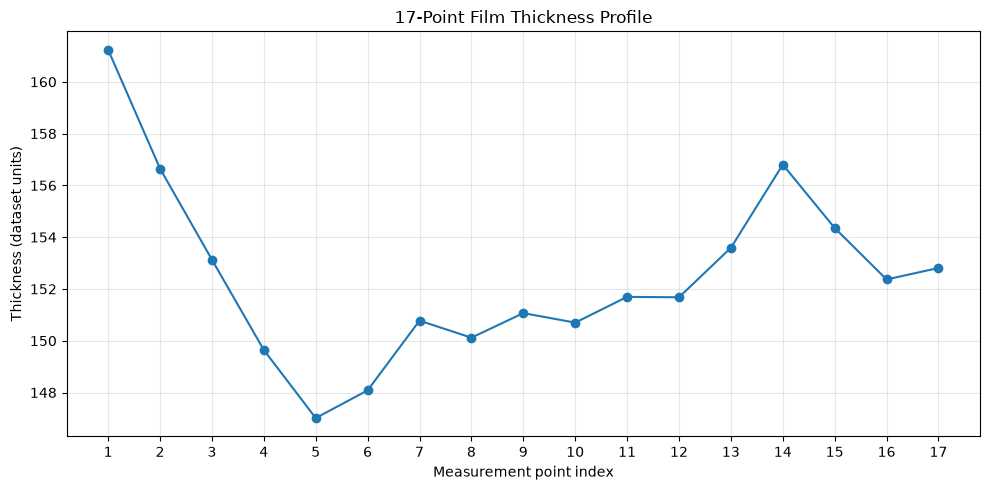

In [6]:
# Identify 17-point measurements

thickness_cols = [
    f"RAW_VALUE_t_{i}"
    for i in range(1, 18)
]

resistance_cols = [
    f"RAW_VALUE_r_{i}"
    for i in range(1, 18)
]

resistivity_cols = [
    f"RAW_VALUE_{i}"
    for i in range(1, 18)
]

points = np.arange(1, 18)

# Select a real wafer for illustration
wafer = df.iloc[0]

print("Wafer ID:", wafer["wafer_id"])

plt.figure(figsize=(10, 5))

plt.plot(
    points,
    wafer[thickness_cols].to_numpy(dtype=float),
    marker="o"
)

plt.title("17-Point Film Thickness Profile")
plt.xlabel("Measurement point index")
plt.ylabel("Thickness (dataset units)")
plt.xticks(points)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


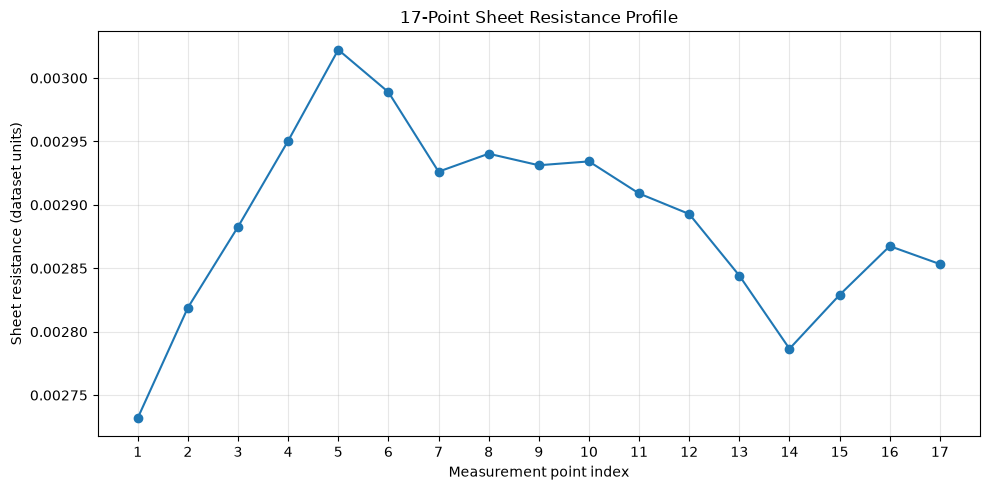

In [7]:
# Sheet resistance profile

plt.figure(figsize=(10, 5))

plt.plot(
    points,
    wafer[resistance_cols].to_numpy(dtype=float),
    marker="o"
)

plt.title("17-Point Sheet Resistance Profile")
plt.xlabel("Measurement point index")
plt.ylabel("Sheet resistance (dataset units)")
plt.xticks(points)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Thickness Uniformity Analysis

Calculate descriptive within-wafer thickness variation using the range and coefficient of variation.

These metrics are exploratory indicators and do not represent undisclosed industrial acceptance limits.

In [8]:
# Calculate thickness variation

thickness_values = df[thickness_cols]

# Work on a copy for derived analytical features
wafer_analysis = df[
    [
        "wafer_id",
        "lot",
        "equipment",
        "mean_thickness",
        "mean_resistance",
        "quality_thickness",
        "quality_resistance",
        "quality_resistivity",
        "quality_overall"
    ]
].copy()

wafer_analysis["thickness_range"] = (
    thickness_values.max(axis=1)
    - thickness_values.min(axis=1)
)

wafer_analysis["thickness_std"] = (
    thickness_values.std(axis=1, ddof=0)
)

wafer_analysis["thickness_cv_pct"] = (
    wafer_analysis["thickness_std"]
    / wafer_analysis["mean_thickness"]
    * 100
)

display(
    wafer_analysis[
        [
            "wafer_id",
            "mean_thickness",
            "thickness_range",
            "thickness_cv_pct"
        ]
    ].head()
)

print("\nThickness variation summary:")
display(
    wafer_analysis[
        ["thickness_range", "thickness_cv_pct"]
    ].describe().round(4)
)


,wafer_id,mean_thickness,thickness_range,thickness_cv_pct
0,V612511104,152.453686,14.226983,2.194470
1,V612511105,152.247616,17.041784,2.592471
2,V612511106,152.749744,13.538581,2.775051
3,V612511116,151.925461,16.261595,2.396409
4,V612515010,152.716449,14.119898,2.191498



Thickness variation summary:


,thickness_range,thickness_cv_pct
count,5208.0000,5208.0000
mean,11.9047,2.4410
std,2.1831,0.4950
min,5.8744,1.4014
25%,10.3413,2.0959
50%,11.7334,2.3699
75%,13.2785,2.7145
max,23.2680,4.2903


## 7. Multi-Parameter Quality Assessment

Investigate wafers that satisfy thickness quality requirements but fail overall quality assessment.

This analysis demonstrates the limitations of thickness-only quality monitoring.

In [9]:
# Multi-parameter quality analysis

overall_bad = df["quality_overall"] == 1

thickness_good = (
    df["quality_thickness"].str.lower() == "good"
)

thickness_good_but_overall_bad = (
    overall_bad & thickness_good
)

total_bad = overall_bad.sum()

missed_by_thickness_only = (
    thickness_good_but_overall_bad.sum()
)

percentage = (
    missed_by_thickness_only / total_bad * 100
)

print("Total overall-bad wafers:", total_bad)

print(
    "Overall-bad wafers with good thickness:",
    missed_by_thickness_only
)

print(
    f"Percentage: {percentage:.2f}%"
)


Total overall-bad wafers: 335
Overall-bad wafers with good thickness: 323
Percentage: 96.42%


## 8. Derived Resistivity Distribution

Analyse the wafer-level average of the 17 derived resistivity measurements. These are post-process derived measurements, not independent sensor readings.

Mean resistivity statistics:


count    5208.000000
mean        0.648660
std         0.005010
min         0.633288
25%         0.646760
50%         0.648288
75%         0.649843
max         0.713022
Name: mean_resistivity, dtype: float64

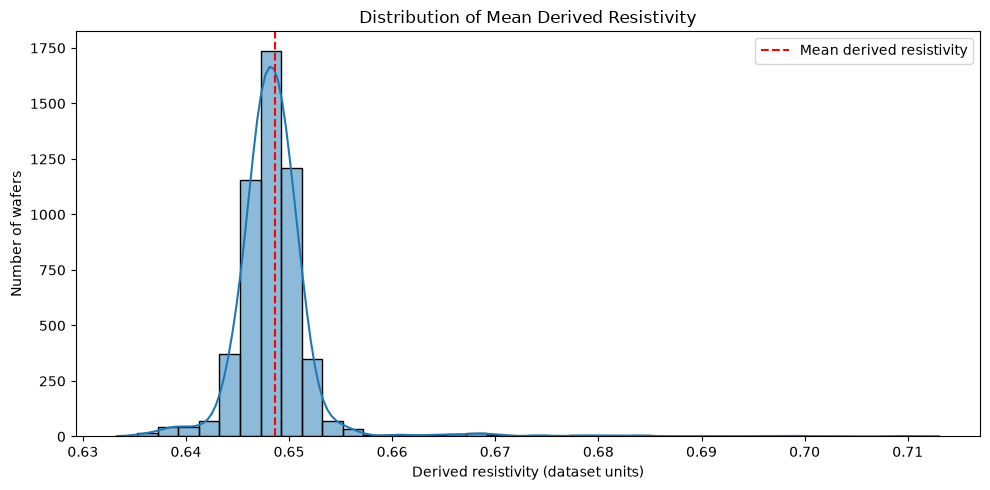

In [10]:
# Calculate mean derived resistivity per wafer

wafer_analysis["mean_resistivity"] = (
    df[resistivity_cols].mean(axis=1)
)

print("Mean resistivity statistics:")
display(
    wafer_analysis["mean_resistivity"]
    .describe()
    .round(6)
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=wafer_analysis,
    x="mean_resistivity",
    bins=40,
    kde=True
)

plt.axvline(
    wafer_analysis["mean_resistivity"].mean(),
    color="red",
    linestyle="--",
    label="Mean derived resistivity"
)

plt.title("Distribution of Mean Derived Resistivity")
plt.xlabel("Derived resistivity (dataset units)")
plt.ylabel("Number of wafers")
plt.legend()

plt.tight_layout()
plt.show()


## 9. Key Findings and Interpretation

### Film Thickness
- Investigated the distribution of average AlCu film thickness.
- Examined the spread and observed range of measurements.
- Visualised individual wafer thickness profiles.

### Electrical Properties
- Investigated the distribution of mean sheet resistance.
- Examined the statistical relationship between thickness and sheet resistance.
- Visualised the 17-point resistance profile.

### Wafer Uniformity
- Calculated thickness range and coefficient of variation.
- Established descriptive measures for comparing
  within-wafer thickness variation.
- Did not assume undisclosed industrial quality thresholds.

### Multi-Parameter Quality Monitoring
- Identified 335 overall-bad wafer records.
- Identified 323 overall-bad wafers with good thickness labels.
- Demonstrated that thickness quality alone does not
  capture all recorded electrical-property quality failures.

### Implications for STRATUM
1. Develop leakage-safe virtual metrology models.
2. Evaluate both thickness and sheet-resistance prediction.
3. Monitor physical and electrical properties separately.
4. Include wafer uniformity and equipment-level analysis.
5. Generate engineering reports grounded in actual data.

### Limitations
- Measurement units require confirmation.
- Exact 17-point wafer coordinates are unavailable.
- Quality thresholds are not publicly disclosed.
- Correlation does not establish physical causation.
- No preprocessing or model training was performed here.